# PTB-XL ECG Representation Learning: CNN vs Autoencoder vs VAE

**Research question:** Does pretraining on unlabeled ECG signals improve multi-label cardiac-condition classification when only a small fraction of training labels is available?

This notebook:
1. Downloads the public PTB-XL 100 Hz recordings from PhysioNet.
2. Builds five diagnostic-superclass labels: NORM, MI, STTC, CD, HYP.
3. Uses the recommended patient-separated folds (1–8 train, 9 validation, 10 test).
4. Compares a 1D CNN trained from scratch with an autoencoder-pretrained CNN and a VAE-pretrained CNN.
5. Repeats supervised training with 10%, 25%, 50%, and 100% of the labeled training subset.
6. Reports macro-F1 and per-label metrics.

**Important:** this is a research prototype, not a clinical diagnostic system. The exact results depend on training settings and dataset labels.

## 0. Enable GPU

In Colab, select **Runtime → Change runtime type → T4 GPU** (or another available GPU) before running the notebook.

In [1]:
!pip -q install wfdb scikit-learn pandas numpy matplotlib tqdm

## 1. Download PTB-XL 100 Hz recordings and metadata

This downloads the `records100` directory (the lower-resolution signals) rather than the additional 500 Hz recordings. The dataset is large, so allow time and ensure your Colab storage has enough space.

In [2]:
import os, subprocess, pathlib, time
from pathlib import Path

ROOT = Path("/content/ptbxl")
ROOT.mkdir(parents=True, exist_ok=True)

# Download metadata directly.
import urllib.request

BASE_URL = "https://physionet.org/files/ptb-xl/1.0.3"
for filename in ["ptbxl_database.csv", "scp_statements.csv"]:
    dest = ROOT / filename
    if not dest.exists():
        print("Downloading", filename)
        urllib.request.urlretrieve(f"{BASE_URL}/{filename}", dest)

# Recursively download the 100 Hz signal directory.
# -N resumes downloads and avoids re-downloading unchanged files.
records_dir = ROOT / "records100"
if not records_dir.exists() or not any(records_dir.rglob("*.dat")):
    cmd = [
        "wget", "-r", "-N", "-c", "-np", "-nH",
        "--cut-dirs=3", "-A", "*.hea,*.dat",
        "-P", str(ROOT),
        f"{BASE_URL}/records100/"
    ]
    print("Downloading PTB-XL 100 Hz recordings...")
    subprocess.run(cmd, check=True)
else:
    print("Found existing records.")

assert (ROOT / "ptbxl_database.csv").exists()
assert (ROOT / "scp_statements.csv").exists()
print("Data folder:", ROOT)
print("Signal files found:", len(list(records_dir.rglob("*.dat"))))

KeyboardInterrupt: 

In [19]:
import os, subprocess
from pathlib import Path
import urllib.request

ROOT = Path("/content/ptbxl")
ROOT.mkdir(parents=True, exist_ok=True)
records_dir = ROOT / "records100"
records_dir.mkdir(parents=True, exist_ok=True)

# 1. Download metadata if missing
BASE_URL = "https://physionet.org/files/ptb-xl/1.0.3"
for filename in ["ptbxl_database.csv", "scp_statements.csv"]:
    dest = ROOT / filename
    if not dest.exists():
        print(f"Downloading {filename}...")
        urllib.request.urlretrieve(f"{BASE_URL}/{filename}", dest)

# 2. Check current files
current_count = len(list(records_dir.rglob("*.dat")))
print(f"Existing .dat files found: {current_count} / 21837")

# 3. Download the single fast archive and extract ONLY the missing files
if current_count < 21837:
    ZIP_PATH = ROOT / "ptbxl.zip"
    ZIP_URL = "https://physionet.org/static/published-projects/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip"

    # Remove partial/corrupt archive if previous attempt was interrupted
    if ZIP_PATH.exists() and ZIP_PATH.stat().st_size < 700 * 1024 * 1024:
        ZIP_PATH.unlink()

    if not ZIP_PATH.exists():
        print("Downloading PTB-XL archive (~800 MB, fast stream)...")
        subprocess.run(["wget", "-c", "-q", "--show-progress", ZIP_URL, "-O", str(ZIP_PATH)], check=True)

    print("Extracting only missing records...")
    # -n prevents overwriting already downloaded files; extracts directly
    extract_cmd = (
        f'unzip -q -n "{ZIP_PATH}" "ptb-xl-*/records100/*" -d /content/temp_extract && '
        f'cp -rn /content/temp_extract/ptb-xl-*/records100/* "{records_dir}/" && '
        f'rm -rf /content/temp_extract "{ZIP_PATH}"'
    )
    subprocess.run(extract_cmd, shell=True, check=True)

assert (ROOT / "ptbxl_database.csv").exists()
assert (ROOT / "scp_statements.csv").exists()
print("Data folder:", ROOT)
print("Signal files found:", len(list(records_dir.rglob("*.dat"))))

Existing .dat files found: 5037 / 21837


KeyboardInterrupt: 

In [21]:
%%bash
# 1. Unzip only records100 from the existing zip (skips already existing files)
unzip -q -n /content/ptbxl/ptbxl.zip "ptb-xl-*/records100/*" -d /content/temp_extract

# 2. Copy extracted records into place and clean up
cp -rn /content/temp_extract/ptb-xl-*/records100/* /content/ptbxl/records100/
rm -rf /content/temp_extract /content/ptbxl/ptbxl.zip

# 3. Check total .dat count
python3 -c "from pathlib import Path; print('Total .dat files:', len(list(Path('/content/ptbxl/records100').rglob('*.dat'))))"

Total .dat files: 5037


[/content/ptbxl/ptbxl.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of /content/ptbxl/ptbxl.zip or
        /content/ptbxl/ptbxl.zip.zip, and cannot find /content/ptbxl/ptbxl.zip.ZIP, period.
cp: warning: behavior of -n is non-portable and may change in future; use --update=none instead
cp: cannot stat '/content/temp_extract/ptb-xl-*/records100/*': No such file or directory


In [22]:
%%bash
# 1. Clean out the broken zip and any temp folder
rm -f /content/ptbxl/ptbxl.zip
rm -rf /content/temp_extract

# 2. Download cleanly via wget with retry and timeout protections
echo "Downloading archive..."
wget -q --show-progress -c --tries=5 --timeout=30 \
  "https://physionet.org/static/published-projects/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip" \
  -O /content/ptbxl/ptbxl.zip

# 3. Unzip only records100 (skipping files already present)
echo "Extracting records..."
unzip -q -n /content/ptbxl/ptbxl.zip "ptb-xl-*/records100/*" -d /content/temp_extract

# 4. Copy missing files into records100 and clean up
cp -rn /content/temp_extract/ptb-xl-*/records100/* /content/ptbxl/records100/
rm -rf /content/temp_extract /content/ptbxl/ptbxl.zip

# 5. Check count
python3 -c "from pathlib import Path; print('Total .dat files:', len(list(Path('/content/ptbxl/records100').rglob('*.dat'))))"

Process is interrupted.


In [23]:
from pathlib import Path
records_dir = Path("/content/ptbxl/records100")
dat_files = list(records_dir.rglob("*.dat"))
print(f"Total .dat files downloaded: {len(dat_files)} / 21837")

Total .dat files downloaded: 5037 / 21837


In [15]:
import os, zipfile, urllib.request, shutil
from pathlib import Path

ROOT = Path("/content/ptbxl")
ZIP_PATH = ROOT / "ptbxl.zip"
ZIP_URL = "https://physionet.org/static/published-projects/ptb-xl/ptb-xl-a-large-publicly-available-electrocardiography-dataset-1.0.3.zip"

print("1. Downloading compressed archive (~800 MB)...")
urllib.request.urlretrieve(ZIP_URL, ZIP_PATH)

print("2. Extracting missing records100...")
with zipfile.ZipFile(ZIP_PATH, 'r') as z:
    for name in z.namelist():
        if "records100/" in name and (name.endswith(".dat") or name.endswith(".hea")):
            z.extract(name, ROOT)

# Flatten nested subfolder if created
sub = list(ROOT.glob("ptb-xl-*"))
if sub and (sub[0] / "records100").exists():
    for f in (sub[0] / "records100").rglob("*"):
        if f.is_file():
            dest = ROOT / "records100" / f.relative_to(sub[0] / "records100")
            dest.parent.mkdir(parents=True, exist_ok=True)
            if not dest.exists():
                shutil.move(str(f), str(dest))
    shutil.rmtree(sub[0], ignore_errors=True)

if ZIP_PATH.exists():
    ZIP_PATH.unlink()

total = len(list((ROOT / "records100").rglob("*.dat")))
print(f"Done! Total .dat files now available: {total} / 21837")

1. Downloading compressed archive (~800 MB)...


KeyboardInterrupt: 

In [17]:
from pathlib import Path
print("Total .dat files:", len(list(Path("/content/ptbxl/records100").rglob("*.dat"))))

Total .dat files: 5037


## 2. Prepare diagnostic labels

We use five broad diagnostic superclasses available in PTB-XL: normal ECG (NORM), myocardial infarction (MI), ST/T changes (STTC), conduction disturbance (CD), and hypertrophy (HYP).

These labels can overlap, so this is **multi-label classification**: a recording may have more than one positive label.

In [24]:
import ast
import numpy as np
import pandas as pd

db = pd.read_csv(ROOT / "ptbxl_database.csv", index_col="ecg_id")
scp = pd.read_csv(ROOT / "scp_statements.csv", index_col=0)

TARGETS = ["NORM", "MI", "STTC", "CD", "HYP"]
scp["diagnostic"] = pd.to_numeric(scp["diagnostic"], errors="coerce").fillna(0).astype(int)

def make_superclass_labels(scp_codes_text):
    codes = ast.literal_eval(scp_codes_text) if isinstance(scp_codes_text, str) else {}
    out = {name: 0 for name in TARGETS}
    for code, score in codes.items():
        if code not in scp.index:
            continue
        row = scp.loc[code]
        if int(row.get("diagnostic", 0)) != 1:
            continue
        superclass = row.get("diagnostic_class", None)
        if superclass in out and float(score) > 0:
            out[superclass] = 1
    return pd.Series(out)

label_df = db["scp_codes"].apply(make_superclass_labels)
db = db.join(label_df)
db["strat_fold"] = pd.to_numeric(db["strat_fold"], errors="coerce").astype(int)

print("Total records in metadata:", len(db))
print("\nLabel counts:")
display(db[TARGETS].sum().rename("positive_records").to_frame())
print("\nRows per fold:")
display(db["strat_fold"].value_counts().sort_index().to_frame("records"))

Total records in metadata: 21799

Label counts:


,positive_records
NORM,9514
MI,5469
STTC,5108
CD,4898
HYP,2649



Rows per fold:


,records
strat_fold,
1,2175
2,2181
3,2192
4,2174
5,2174
6,2173
7,2176
8,2173
9,2183


## 3. Choose a manageable, patient-separated subset

To keep the notebook practical in Colab, we sample a subset from the official folds. The split remains patient-separated because we keep the official folds intact.

- Folds 1–8: training and unsupervised pretraining
- Fold 9: validation and threshold selection
- Fold 10: final test

The signal download is still the full 100 Hz directory, but only selected recordings are loaded into RAM.

In [25]:
SEED = 42
rng = np.random.default_rng(SEED)

# Only keep records that exist on your disk
existing_ids = set()
for ecg_id, row in db.iterrows():
    if (ROOT / f"{row['filename_lr']}.dat").exists():
        existing_ids.add(ecg_id)

db_available = db.loc[sorted(list(existing_ids))].copy()
print(f"Usable records available locally: {len(db_available)}")

train_meta_all = db_available[db_available["strat_fold"].between(1, 8)].copy()
val_meta_all   = db_available[db_available["strat_fold"] == 9].copy()
test_meta_all  = db_available[db_available["strat_fold"] == 10].copy()

# Automatically fit into whatever records you currently have downloaded
TRAIN_RECORDS = min(3500, len(train_meta_all))
VAL_RECORDS   = min(500, len(val_meta_all))
TEST_RECORDS  = min(500, len(test_meta_all))

def sample_rows(frame, n, seed):
    if len(frame) <= n:
        return frame.copy()
    return frame.sample(n=n, random_state=seed).copy()

train_meta = sample_rows(train_meta_all, TRAIN_RECORDS, SEED).sort_index()
val_meta   = sample_rows(val_meta_all, VAL_RECORDS, SEED + 1).sort_index()
test_meta  = sample_rows(test_meta_all, TEST_RECORDS, SEED + 2).sort_index()

print("Selected train/val/test:", len(train_meta), len(val_meta), len(test_meta))
display(train_meta[TARGETS].sum().rename("positive_records").to_frame())

Usable records available locally: 5037
Selected train/val/test: 3500 500 500


,positive_records
NORM,1838
MI,640
STTC,762
CD,740
HYP,376


## 4. Load the selected ECG signals

Each 100 Hz recording should have 1,000 time points and 12 leads. We use the same selected train, validation, and test records for every model.

If a record is missing or corrupt, the loader reports it and skips it. If many files are missing, check that the download cell completed successfully.

In [26]:
import wfdb
from tqdm.auto import tqdm

def read_signal(meta):
    # PTB-XL metadata stores paths such as records100/00000/00001_lr
    rel = str(meta["filename_lr"])
    record_path = ROOT / rel
    signal, fields = wfdb.rdsamp(str(record_path))
    # WFDB returns [time, leads]; model expects [leads, time].
    signal = signal.astype(np.float32).T
    if signal.shape != (12, 1000):
        raise ValueError(f"Unexpected signal shape {signal.shape} for {record_path}")
    return signal

def load_signals(meta, name):
    xs, ys, kept_ids = [], [], []
    failed = []
    for ecg_id, row in tqdm(meta.iterrows(), total=len(meta), desc=f"Loading {name}"):
        try:
            xs.append(read_signal(row))
            ys.append(row[TARGETS].to_numpy(dtype=np.float32))
            kept_ids.append(ecg_id)
        except Exception as e:
            failed.append((ecg_id, str(e)))
    if failed:
        print(f"{name}: skipped {len(failed)} failed records; first error:", failed[0])
    X = np.stack(xs).astype(np.float32)
    Y = np.stack(ys).astype(np.float32)
    return X, Y, np.asarray(kept_ids)

X_train_raw, y_train, train_ids = load_signals(train_meta, "train")
X_val_raw, y_val, val_ids = load_signals(val_meta, "validation")
X_test_raw, y_test, test_ids = load_signals(test_meta, "test")

print("Shapes:", X_train_raw.shape, y_train.shape, X_val_raw.shape, X_test_raw.shape)

Loading train:   0%|          | 0/3500 [00:00<?, ?it/s]

Loading validation:   0%|          | 0/500 [00:00<?, ?it/s]

Loading test:   0%|          | 0/500 [00:00<?, ?it/s]

Shapes: (3500, 12, 1000) (3500, 5) (500, 12, 1000) (500, 12, 1000)


## 5. Normalize signals and make PyTorch datasets

We estimate per-lead mean and standard deviation from training recordings only, then apply them to validation and test signals. This avoids using test data to fit preprocessing.

In [27]:
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader
import torch.nn.functional as F

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

# Compute per-lead statistics using training data only.
lead_mean = X_train_raw.mean(axis=(0, 2), keepdims=True)  # [1, 12, 1]
lead_std = X_train_raw.std(axis=(0, 2), keepdims=True)
lead_std = np.maximum(lead_std, 1e-6)

X_train = ((X_train_raw - lead_mean) / lead_std).astype(np.float32)
X_val = ((X_val_raw - lead_mean) / lead_std).astype(np.float32)
X_test = ((X_test_raw - lead_mean) / lead_std).astype(np.float32)

class ECGDataset(Dataset):
    def __init__(self, X, y=None):
        self.X = torch.from_numpy(X)
        self.y = None if y is None else torch.from_numpy(y.astype(np.float32))
    def __len__(self):
        return len(self.X)
    def __getitem__(self, idx):
        if self.y is None:
            return self.X[idx]
        return self.X[idx], self.y[idx]

BATCH_SIZE = 64
train_unsup_loader = DataLoader(ECGDataset(X_train), batch_size=BATCH_SIZE, shuffle=True, num_workers=0)

Device: cuda


## 6. Define the shared 1D CNN encoder, autoencoder, VAE, and classifier

All three classifiers use the same convolutional encoder architecture. The difference is how the encoder is initialized:
- CNN baseline: random initialization, trained using labels.
- AE-pretrained: first trained to reconstruct ECG signals.
- VAE-pretrained: first trained to learn a probabilistic latent representation and reconstruct ECG signals.

This makes the comparison more controlled than comparing unrelated architectures.

In [28]:
class ECGEncoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv1d(12, 32, kernel_size=7, stride=2, padding=3),
            nn.BatchNorm1d(32), nn.ReLU(),
            nn.Conv1d(32, 64, kernel_size=7, stride=2, padding=3),
            nn.BatchNorm1d(64), nn.ReLU(),
            nn.Conv1d(64, 128, kernel_size=7, stride=2, padding=3),
            nn.BatchNorm1d(128), nn.ReLU(),
            nn.AdaptiveAvgPool1d(8)
        )
        self.fc = nn.Linear(128 * 8, latent_dim)
    def forward(self, x):
        h = self.conv(x).flatten(1)
        return self.fc(h)

class ECGDecoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.fc = nn.Linear(latent_dim, 128 * 8)
        self.conv1 = nn.Sequential(nn.Conv1d(128, 64, 5, padding=2), nn.ReLU())
        self.conv2 = nn.Sequential(nn.Conv1d(64, 32, 5, padding=2), nn.ReLU())
        self.conv3 = nn.Conv1d(32, 12, 5, padding=2)
    def forward(self, z):
        x = self.fc(z).view(-1, 128, 8)
        x = F.interpolate(x, size=125, mode="linear", align_corners=False)
        x = self.conv1(x)
        x = F.interpolate(x, size=250, mode="linear", align_corners=False)
        x = self.conv2(x)
        x = F.interpolate(x, size=500, mode="linear", align_corners=False)
        x = F.interpolate(x, size=1000, mode="linear", align_corners=False)
        return self.conv3(x)

class ECGAutoencoder(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.encoder = ECGEncoder(latent_dim)
        self.decoder = ECGDecoder(latent_dim)
    def forward(self, x):
        z = self.encoder(x)
        return self.decoder(z)

class ECGVAE(nn.Module):
    def __init__(self, latent_dim=128):
        super().__init__()
        self.backbone = ECGEncoder(latent_dim)
        self.mu = nn.Linear(latent_dim, latent_dim)
        self.logvar = nn.Linear(latent_dim, latent_dim)
        self.decoder = ECGDecoder(latent_dim)
    def encode(self, x):
        h = self.backbone(x)
        return self.mu(h), self.logvar(h).clamp(-8, 8)
    def reparameterize(self, mu, logvar):
        std = torch.exp(0.5 * logvar)
        return mu + torch.randn_like(std) * std
    def forward(self, x):
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decoder(z), mu, logvar

class ECGClassifier(nn.Module):
    def __init__(self, encoder=None, latent_dim=128):
        super().__init__()
        self.encoder = ECGEncoder(latent_dim) if encoder is None else encoder
        self.head = nn.Sequential(
            nn.Linear(latent_dim, 128), nn.ReLU(), nn.Dropout(0.25),
            nn.Linear(128, len(TARGETS))
        )
    def forward(self, x):
        return self.head(self.encoder(x))

print("Models defined.")

Models defined.


## 7. Pretrain the autoencoder and VAE using training signals only

This step does not use disease labels. Reconstruction loss measures how closely the decoder reproduces the input ECG.

For the VAE, the loss also includes a KL-divergence term that encourages a structured latent distribution. The weight is intentionally small; it can be tuned if reconstruction collapses or the latent space is not useful.

AE epoch 1/5:   0%|          | 0/55 [00:00<?, ?it/s]

AE epoch 1: reconstruction MSE=0.93992


AE epoch 2/5:   0%|          | 0/55 [00:00<?, ?it/s]

AE epoch 2: reconstruction MSE=0.88628


AE epoch 3/5:   0%|          | 0/55 [00:00<?, ?it/s]

...

VAE epoch 3: total loss=0.95374


VAE epoch 4/5:   0%|          | 0/55 [00:00<?, ?it/s]

VAE epoch 4: total loss=0.94492


VAE epoch 5/5:   0%|          | 0/55 [00:00<?, ?it/s]

VAE epoch 5: total loss=0.95519


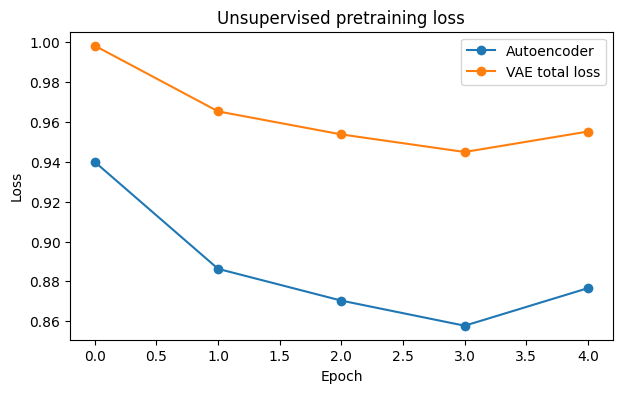

In [29]:
def pretrain_autoencoder(model, loader, epochs=50, lr=1e-3):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        model.train()
        total, n = 0.0, 0
        for xb in tqdm(loader, leave=False, desc=f"AE epoch {epoch+1}/{epochs}"):
            xb = xb.to(DEVICE)
            opt.zero_grad()
            recon = model(xb)
            loss = F.mse_loss(recon, xb)
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
            n += len(xb)
        history.append(total / n)
        print(f"AE epoch {epoch+1}: reconstruction MSE={history[-1]:.5f}")
    return model, history

def pretrain_vae(model, loader, epochs=5, lr=1e-3, beta=1e-3):
    model = model.to(DEVICE)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    history = []
    for epoch in range(epochs):
        model.train()
        total, n = 0.0, 0
        for xb in tqdm(loader, leave=False, desc=f"VAE epoch {epoch+1}/{epochs}"):
            xb = xb.to(DEVICE)
            opt.zero_grad()
            recon, mu, logvar = model(xb)
            recon_loss = F.mse_loss(recon, xb)
            kl = -0.5 * (1 + logvar - mu.pow(2) - logvar.exp()).sum(dim=1).mean()
            loss = recon_loss + beta * kl
            loss.backward()
            opt.step()
            total += loss.item() * len(xb)
            n += len(xb)
        history.append(total / n)
        print(f"VAE epoch {epoch+1}: total loss={history[-1]:.5f}")
    return model, history

PRETRAIN_EPOCHS = 5  # Increase to 10–20 if time permits.
LATENT_DIM = 128

ae = ECGAutoencoder(LATENT_DIM)
ae, ae_history = pretrain_autoencoder(ae, train_unsup_loader, epochs=PRETRAIN_EPOCHS)

vae = ECGVAE(LATENT_DIM)
vae, vae_history = pretrain_vae(vae, train_unsup_loader, epochs=PRETRAIN_EPOCHS)

import matplotlib.pyplot as plt
plt.figure(figsize=(7, 4))
plt.plot(ae_history, marker="o", label="Autoencoder")
plt.plot(vae_history, marker="o", label="VAE total loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Unsupervised pretraining loss")
plt.legend()
plt.show()

## 8. Training and evaluation helpers

We use binary cross-entropy with logits because each ECG can have multiple diagnostic labels. The model outputs five independent probabilities.

In [39]:
from sklearn.metrics import f1_score, roc_auc_score, average_precision_score, classification_report
from copy import deepcopy

def make_loader(X, y, indices, shuffle):
    ds = ECGDataset(X[indices], y[indices])
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=0)


def train_classifier(
    model,
    train_loader,
    val_loader,
    epochs=50,
    lr=1e-3,
    patience=5,
    min_delta=1e-4
):
    model = model.to(DEVICE)

    optimizer = torch.optim.AdamW(
        model.parameters(),
        lr=lr,
        weight_decay=1e-4
    )

    best_val_loss = float("inf")
    best_state = deepcopy(model.state_dict())
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "val_loss": []
    }

    for epoch in range(epochs):

        # 1. Train
        model.train()
        train_total = 0.0
        train_count = 0

        for xb, yb in train_loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            optimizer.zero_grad()

            logits = model(xb)
            loss = F.binary_cross_entropy_with_logits(
                logits, yb
            )

            loss.backward()
            optimizer.step()

            train_total += loss.item() * len(xb)
            train_count += len(xb)

        train_loss = train_total / train_count

        # 2. Validate without updating weights
        model.eval()
        val_total = 0.0
        val_count = 0

        with torch.no_grad():
            for xb, yb in val_loader:
                xb = xb.to(DEVICE)
                yb = yb.to(DEVICE)

                logits = model(xb)
                loss = F.binary_cross_entropy_with_logits(
                    logits, yb
                )

                val_total += loss.item() * len(xb)
                val_count += len(xb)

        val_loss = val_total / val_count

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # 3. Save the best model
        if val_loss < best_val_loss - min_delta:
            best_val_loss = val_loss
            best_state = deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        print(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train loss: {train_loss:.4f} | "
            f"Val loss: {val_loss:.4f} | "
            f"No improvement: "
            f"{epochs_without_improvement}/{patience}"
        )

        # 4. Stop if validation loss no longer improves
        if epochs_without_improvement >= patience:
            print(
                f"Early stopping at epoch {epoch + 1}. "
                f"Best validation loss: {best_val_loss:.4f}"
            )
            break

    # Restore the best validation checkpoint
    model.load_state_dict(best_state)

    return model, history


@torch.no_grad()
def predict_probs(model, X, batch_size=128):
    model.eval()
    outputs = []
    for start in range(0, len(X), batch_size):
        xb = torch.from_numpy(X[start:start+batch_size]).to(DEVICE)
        outputs.append(torch.sigmoid(model(xb)).cpu().numpy())
    return np.concatenate(outputs, axis=0)

def best_thresholds(y_true, probs):
    # Select one threshold per label using validation F1.
    thresholds = []
    for j in range(y_true.shape[1]):
        candidates = np.linspace(0.1, 0.9, 17)
        scores = [f1_score(y_true[:, j], probs[:, j] >= t, zero_division=0) for t in candidates]
        thresholds.append(float(candidates[int(np.argmax(scores))]))
    return np.array(thresholds)

def evaluate_model(name, model, X_val, y_val, X_test, y_test):
    val_probs = predict_probs(model, X_val)
    thresholds = best_thresholds(y_val, val_probs)
    val_pred = (val_probs >= thresholds).astype(int)
    val_macro_f1 = f1_score(y_val, val_pred, average="macro", zero_division=0)

    # The held-out test set is used only for final reporting, not model selection.
    test_probs = predict_probs(model, X_test)
    pred = (test_probs >= thresholds).astype(int)
    macro_f1 = f1_score(y_test, pred, average="macro", zero_division=0)
    micro_f1 = f1_score(y_test, pred, average="micro", zero_division=0)
    per_label_f1 = f1_score(y_test, pred, average=None, zero_division=0)
    try:
        macro_auroc = roc_auc_score(y_test, test_probs, average="macro")
    except ValueError:
        macro_auroc = np.nan
    try:
        macro_auprc = average_precision_score(y_test, test_probs, average="macro")
    except ValueError:
        macro_auprc = np.nan
    row = {
        "model": name, "val_macro_f1": val_macro_f1,
        "macro_f1": macro_f1, "micro_f1": micro_f1,
        "macro_auroc": macro_auroc, "macro_auprc": macro_auprc
    }
    for label, score in zip(TARGETS, per_label_f1):
        row[f"F1_{label}"] = score
    return row, thresholds, test_probs

## 9. Compare the models at 10%, 25%, 50%, and 100% labeled data

The autoencoder and VAE are pretrained once on the training signals without labels. For each labeled-data fraction, we train:
1. CNN from scratch.
2. Classifier initialized with the pretrained autoencoder encoder.
3. Classifier initialized with the pretrained VAE encoder.

For a fair test, the same labeled subset is used for all three models at each fraction. This cell is the main experiment and may take some time.

In [40]:
SUPERVISED_EPOCHS = 50
FRACTIONS = [0.10, 0.25, 0.50, 1.00]

# Reproducible subset order; the same prefixes are used across model types.
perm = np.random.default_rng(SEED).permutation(len(X_train))
val_indices = np.arange(len(X_val))

results = []
saved_models = {}

# Store pretrained encoder weights so each experiment starts from the same initialization.
ae_encoder_state = deepcopy(ae.encoder.state_dict())
vae_encoder_state = deepcopy(vae.backbone.state_dict())

for fraction in FRACTIONS:
    n_labeled = max(100, int(len(X_train) * fraction))
    labeled_indices = perm[:n_labeled]
    train_loader = make_loader(X_train, y_train, labeled_indices, shuffle=True)
    val_loader = make_loader(X_val, y_val, val_indices, shuffle=False)
    print(f"\nLabeled fraction: {fraction:.0%} ({n_labeled} records)")

    # Model 1: baseline CNN trained from scratch.
    torch.manual_seed(SEED)
    cnn = ECGClassifier(latent_dim=LATENT_DIM)
    cnn, _ = train_classifier(cnn, train_loader, val_loader, epochs=SUPERVISED_EPOCHS)
    row, thresholds, probs = evaluate_model(f"CNN_{fraction:.2f}", cnn, X_val, y_val, X_test, y_test)
    row["labeled_fraction"] = fraction
    row["n_labeled"] = n_labeled
    results.append(row)
    saved_models[(fraction, "CNN")] = {"model": cnn, "thresholds": thresholds}

    # Model 2: autoencoder-pretrained encoder.
    torch.manual_seed(SEED)
    ae_encoder = ECGEncoder(LATENT_DIM)
    ae_encoder.load_state_dict(ae_encoder_state)
    ae_clf = ECGClassifier(encoder=ae_encoder, latent_dim=LATENT_DIM)
    ae_clf, _ = train_classifier(ae_clf, train_loader, val_loader, epochs=SUPERVISED_EPOCHS)
    row, thresholds, probs = evaluate_model(f"AE_{fraction:.2f}", ae_clf, X_val, y_val, X_test, y_test)
    row["labeled_fraction"] = fraction
    row["n_labeled"] = n_labeled
    results.append(row)
    saved_models[(fraction, "AE")] = {"model": ae_clf, "thresholds": thresholds}

    # Model 3: VAE-pretrained encoder.
    torch.manual_seed(SEED)
    vae_encoder = ECGEncoder(LATENT_DIM)
    vae_encoder.load_state_dict(vae_encoder_state)
    vae_clf = ECGClassifier(encoder=vae_encoder, latent_dim=LATENT_DIM)
    vae_clf, _ = train_classifier(vae_clf, train_loader, val_loader, epochs=SUPERVISED_EPOCHS)
    row, thresholds, probs = evaluate_model(f"VAE_{fraction:.2f}", vae_clf, X_val, y_val, X_test, y_test)
    row["labeled_fraction"] = fraction
    row["n_labeled"] = n_labeled
    results.append(row)
    saved_models[(fraction, "VAE")] = {"model": vae_clf, "thresholds": thresholds}

    # Save interim results in case the Colab runtime disconnects later.
    pd.DataFrame(results).to_csv(ROOT / "experiment_results_interim.csv", index=False)

results_df = pd.DataFrame(results)
display(results_df.sort_values(["labeled_fraction", "macro_f1"], ascending=[True, False]))


Labeled fraction: 10% (350 records)
Epoch 1/50 | Train loss: 0.5960 | Val loss: 0.6514 | No improvement: 0/5
Epoch 2/50 | Train loss: 0.5045 | Val loss: 0.5653 | No improvement: 0/5
Epoch 3/50 | Train loss: 0.4549 | Val loss: 0.4806 | No improvement: 0/5
Epoch 4/50 | Train loss: 0.4352 | Val loss: 0.4438 | No improvement: 0/5
Epoch 5/50 | Train loss: 0.4111 | Val loss: 0.4365 | No improvement: 0/5
Epoch 6/50 | Train loss: 0.3910 | Val loss: 0.4258 | No improvement: 0/5
Epoch 7/50 | Train loss: 0.3591 | Val loss: 0.4108 | No improvement: 0/5
Epoch 8/50 | Train loss: 0.3436 | Val loss: 0.4416 | No improvement: 1/5
Epoch 9/50 | Train loss: 0.3300 | Val loss: 0.4339 | No improvement: 2/5
Epoch 10/50 | Train loss: 0.3081 | Val loss: 0.4935 | No improvement: 3/5
Epoch 11/50 | Train loss: 0.2904 | Val loss: 0.4721 | No improvement: 4/5
Epoch 12/50 | Train loss: 0.2694 | Val loss: 0.4405 | No improvement: 5/5
Early stopping at epoch 12. Best validation loss: 0.4108
Epoch 1/50 | Train loss: 0.

,model,val_macro_f1,macro_f1,micro_f1,macro_auroc,macro_auprc,F1_NORM,F1_MI,F1_STTC,F1_CD,F1_HYP,labeled_fraction,n_labeled
2,VAE_0.10,0.614151,0.529228,0.587106,0.767427,0.510208,0.790262,0.418773,0.611111,0.439252,0.386740,0.10,350
0,CNN_0.10,0.580647,0.509925,0.588563,0.772093,0.476254,0.806026,0.433735,0.580247,0.337209,0.392405,0.10,350
1,AE_0.10,0.561520,0.487137,0.549070,0.738882,0.449482,0.773960,0.412698,0.527607,0.335878,0.385542,0.10,350
3,CNN_0.25,0.633154,0.589632,0.650499,0.825727,0.579374,0.827324,0.487603,0.644518,0.557576,0.431138,0.25,875
5,VAE_0.25,0.601773,0.544410,0.616935,0.787615,0.543753,0.820244,0.462687,0.600000,0.450549,0.388571,0.25,875
4,AE_0.25,0.600218,0.534879,0.597458,0.783124,0.529353,0.795367,0.453333,0.577181,0.457711,0.390805,0.25,875
7,AE_0.50,0.670422,0.626124,0.691729,0.842951,0.633144,0.836096,0.519231,0.704626,0.552147,0.518519,0.50,1750
6,CNN_0.50,0.665007,0.623624,0.683133,0.849412,0.649806,0.851590,0.528455,0.693548,0.601227,0.443299,0.50,1750
8,VAE_0.50,0.664904,0.580543,0.644043,0.824115,0.617732,0.809612,0.509653,0.666667,0.480000,0.436782,0.50,1750
10,AE_1.00,0.698512,0.666282,0.721875,0.873813,0.731469,0.850829,0.555024,0.734513,0.597826,0.593220,1.00,3500


## 10. Visualize the main result

The key chart compares macro-F1 across labeled-data fractions. Use it to answer whether pretraining helps most when only a small fraction of labels is available.

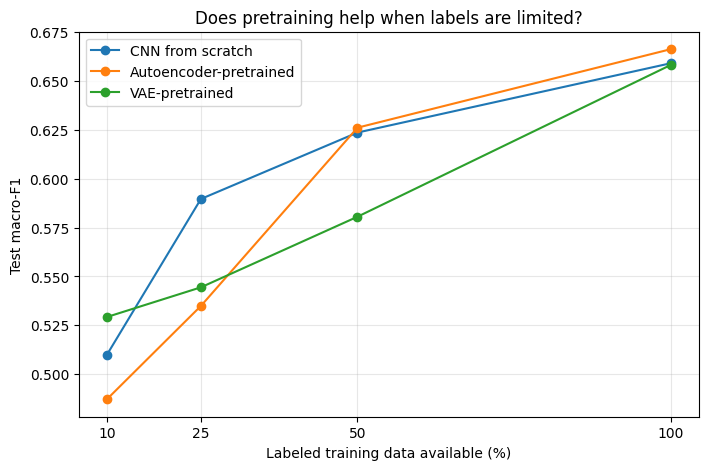

In [41]:
plt.figure(figsize=(8, 5))
for model_prefix, label in [("CNN", "CNN from scratch"), ("AE", "Autoencoder-pretrained"), ("VAE", "VAE-pretrained")]:
    subset = results_df[results_df["model"].str.startswith(model_prefix + "_")].sort_values("labeled_fraction")
    plt.plot(subset["labeled_fraction"] * 100, subset["macro_f1"], marker="o", label=label)
plt.xlabel("Labeled training data available (%)")
plt.ylabel("Test macro-F1")
plt.title("Does pretraining help when labels are limited?")
plt.xticks([10, 25, 50, 100])
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

## 11. Inspect per-label results for one selected fraction

Choose a fraction to examine. These results use thresholds selected on validation data, then report the held-out test set.

,model,macro_f1,micro_f1,macro_auroc,macro_auprc,F1_NORM,F1_MI,F1_STTC,F1_CD,F1_HYP
0,CNN_0.10,0.509925,0.588563,0.772093,0.476254,0.806026,0.433735,0.580247,0.337209,0.392405
1,AE_0.10,0.487137,0.549070,0.738882,0.449482,0.773960,0.412698,0.527607,0.335878,0.385542
2,VAE_0.10,0.529228,0.587106,0.767427,0.510208,0.790262,0.418773,0.611111,0.439252,0.386740


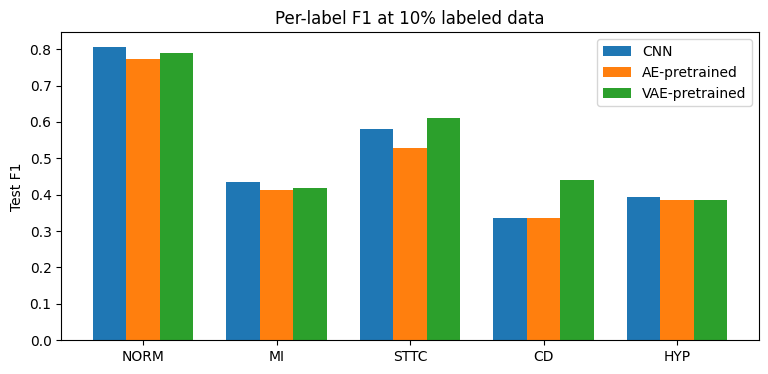

In [42]:
chosen_fraction = 0.10  # Change to 0.25, 0.50, or 1.00
rows = results_df[np.isclose(results_df["labeled_fraction"], chosen_fraction)]
display(rows[["model", "macro_f1", "micro_f1", "macro_auroc", "macro_auprc"] + [f"F1_{t}" for t in TARGETS]])

plt.figure(figsize=(9, 4))
x = np.arange(len(TARGETS))
width = 0.25
for i, (prefix, name) in enumerate([("CNN", "CNN"), ("AE", "AE-pretrained"), ("VAE", "VAE-pretrained")]):
    row = rows[rows["model"].str.startswith(prefix + "_")].iloc[0]
    values = [row[f"F1_{t}"] for t in TARGETS]
    plt.bar(x + (i - 1) * width, values, width, label=name)
plt.xticks(x, TARGETS)
plt.ylabel("Test F1")
plt.title(f"Per-label F1 at {chosen_fraction:.0%} labeled data")
plt.legend()
plt.show()

## 12. Save results and model weights

Download the result table and (optionally) the trained model weights. The weights can be large; save only the models you need for your report.

In [43]:
results_path = ROOT / "ptbxl_representation_learning_results.csv"
results_df.to_csv(results_path, index=False)
print("Saved:", results_path)

# Save the best-performing row's model at each fraction based on macro-F1.
import torch
for fraction in FRACTIONS:
    subset = results_df[np.isclose(results_df["labeled_fraction"], fraction)]
    best_row = subset.loc[subset["val_macro_f1"].idxmax()]
    model_name = best_row["model"].split("_")[0]
    bundle = saved_models[(fraction, model_name)]
    save_path = ROOT / f"best_model_{int(fraction*100)}pct.pt"
    torch.save({
        "state_dict": bundle["model"].state_dict(),
        "model_type": model_name,
        "labeled_fraction": fraction,
        "thresholds": bundle["thresholds"],
        "targets": TARGETS,
        "lead_mean": lead_mean,
        "lead_std": lead_std
    }, save_path)
    print("Saved:", save_path)

from google.colab import files
files.download(str(results_path))

Saved: /content/ptbxl/ptbxl_representation_learning_results.csv
Saved: /content/ptbxl/best_model_10pct.pt
Saved: /content/ptbxl/best_model_25pct.pt
Saved: /content/ptbxl/best_model_50pct.pt
Saved: /content/ptbxl/best_model_100pct.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 13. How to write the conclusion

Do not assume that the pretrained models win. Use your actual results.

Answer these questions:
1. Which model achieved the highest macro-F1 at 10% labeled data?
2. Does the ranking change when 100% of labels are available?
3. Which diagnostic labels are hardest to predict?
4. Does pretraining improve rare-label recall, or only the common labels?
5. Are the differences large and consistent enough to matter?

### Limitations to report
- PTB-XL labels are clinical annotations and may be imperfect.
- The five superclasses are not mutually exclusive.
- Results depend on the chosen subset, model capacity, and training duration.
- A dataset benchmark does not establish clinical safety or real-world generalization.
- The experiment investigates label efficiency; it does not demonstrate that AI can replace clinicians.

In [44]:
import zipfile
from google.colab import files
from pathlib import Path

# Bundle all 4 saved model checkpoints into a single zip
zip_filename = "/content/ptbxl_latest_models_50ep.zip"
model_files = [
    "/content/ptbxl/best_model_10pct.pt",
    "/content/ptbxl/best_model_25pct.pt",
    "/content/ptbxl/best_model_50pct.pt",
    "/content/ptbxl/best_model_100pct.pt",
]

with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
    for file_path in model_files:
        p = Path(file_path)
        if p.exists():
            zipf.write(p, arcname=p.name)
            print(f"Added {p.name}")

# Trigger browser download of the single archive
files.download(zip_filename)

Added best_model_10pct.pt
Added best_model_25pct.pt
Added best_model_50pct.pt
Added best_model_100pct.pt


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
`